# MOSH vs new UCSF applicator

This notebook compares the MOSH applicator to the new UCSF applicator. Once tested with a sample run of the UCSF applicator, it will be adapted into a standardized format that allows end-users to easily input new parameters and automatically generate a comparison.

In [1]:
import sys
sys.path.insert(0, "../")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from matplotlib import ticker
from math import pi
from decimal import Decimal
from mosh_src.plotting_functions import *

In [3]:
# Set parameters for UCSF plots
z_slice_ucsf = 25
bins_ucsf = 85
dose_grid_half_ucsf = 2.5
lattice_ucsf = dose_grid_half_ucsf*2/bins_ucsf
source_transZ_ucsf = -0.5
source_plane_ucsf = cm_to_voxel(np.array(source_transZ_ucsf), bins_ucsf, dose_grid_half_ucsf*2/bins_ucsf)

In [4]:
# Set parameters for MOSH plots
z_slice_mosh = 25
bins_mosh = 85
dose_grid_half_mosh = 2.5
lattice_mosh = dose_grid_half_mosh*2/bins_mosh
source_transZ_mosh = -0.5
source_plane_mosh = cm_to_voxel(np.array(source_transZ_mosh), bins_mosh, dose_grid_half_mosh*2/bins_mosh)

In [5]:
# Common parameters
#norm_point = (0.0, 0.3) # deprecated in favor of dose_point below
applicator_rad = 0.3
source_rad = [0.03, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rngX = (-2.5, 2.5)
rngY = (-2.5, 2.5)

## Comparison - basic architecture

What do we want to compare? Values that we care about include:

    - Mucosal dose of each applicator, defined as dose delivered at edge of applicator (just outside r = 0.3 cm)
    - Dose delivered to ROI
    - Dose delivered everywhere except the ROI (initially, will include the mucosal dose)

To compare these values between MOSH and UCSF:

    - Sum of dose delivered in each region (e.g. sum all voxels in a given region) and make direct comparison
    - Plot dose at constant angle (for ROI) or constant radius (for mucosal dose)
    - Subtract doses and produce contour plot of difference to observe "hotspots"
    - Others?

## Comparison - single ROI to "north" of position 1

In [6]:
# Step 1: define ROI
# Simple ROI = cubical region centered @ 0.5 cm from edge of applicator, 0.2 cm to each side
# Units = cm
x0 = -0.1
x1 = 0.1
y0 = 0.40
y1 = 0.60
roi_side = 0.2

roi = np.array([x0, x1, y0, y1])

# Convert ROI definition to voxel space - UCSF
roi_vox_ucsf = cm_to_voxel(roi, bins_ucsf, lattice_ucsf)
print(roi_vox_ucsf)

# Convert ROI definition to voxel space - MOSH
roi_vox_mosh = cm_to_voxel(roi, bins_mosh, lattice_mosh)
print(roi_vox_mosh)

[40 44 49 52]
[40 44 49 52]


In [7]:
# Define dose - we set the same point to dose in UCSF and MOSH plots
dose = 20 # Gy
dose_point = (0.0, 0.5) # cm - in center of roi

In [8]:
# Step 2: load each applicator distribution
# UCSF
ucsf = "/Users/seanmullane/Desktop/Research_2023/Sept_outputs/ucsf_123removed_1e7_85bins_2.5cmHL.csv"

norm_energy_u, voxel_u = extract_norm_energy(ucsf, source_plane_ucsf, 2, dose_point, bins_ucsf, lattice_ucsf)

Xu, Yu, energyu, __ = contour_energy(ucsf, (bins_ucsf, bins_ucsf), dose_grid_half_ucsf, source_plane_ucsf, 2, rngX, rngY, source_rad=source_rad[4], 
                                               scale=True, norm_energy=norm_energy_u, dose=dose, zero_source=True, std_dev=False)

print(energyu[voxel_u[0]][voxel_u[1]])
print(voxel_u)

20.0
[42 50]


In [9]:
# MOSH
mosh = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_10_5rod_6rod/5rods_12oclock_open_1e7_85bins_2.5cmHL.csv"

norm_energy_m, voxel_m = extract_norm_energy(mosh, source_plane_mosh, 2, dose_point, bins_mosh, lattice_mosh)

Xm, Ym, energym, __ = contour_energy(mosh, (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane_mosh, 2, rngX, rngY, source_rad=source_rad[4], 
                                               scale=True, norm_energy=norm_energy_m, dose=dose, zero_source=True, std_dev=False)

print(energym[voxel_m[0]][voxel_m[1]])
print(voxel_m)

20.0
[42 50]


In [10]:
# Extract dose in ROI for each applicator
# UCSF
roi_dose_ucsf = energyu[roi_vox_ucsf[0]:roi_vox_ucsf[1], roi_vox_ucsf[2]:roi_vox_ucsf[3]]
print(np.shape(roi_dose_ucsf))

# MOSH
roi_dose_mosh = energym[roi_vox_mosh[0]:roi_vox_mosh[1], roi_vox_mosh[2]:roi_vox_mosh[3]]
print(np.shape(roi_dose_mosh))

(4, 3)
(4, 3)


In [11]:
# Compare total dose delivered to ROI for each applicator
# Also need to combine std dev here + report those values!
# This is difficult because adjacent voxels do not have independent energy values
total_dose_ucsf = np.sum(roi_dose_ucsf)
print("UCSF: " + str(total_dose_ucsf))

total_dose_mosh = np.sum(roi_dose_mosh)
print("MOSH: " + str(total_dose_mosh))

UCSF: 219.44987792193126
MOSH: 226.5792711309438


In [12]:
# Compare total dose delivered to everywhere except the ROI for each applicator
non_roi_dose_ucsf = np.sum(energyu) - total_dose_ucsf
non_roi_dose_mosh = np.sum(energym) - total_dose_mosh

# Need to exclude area in center of applicator

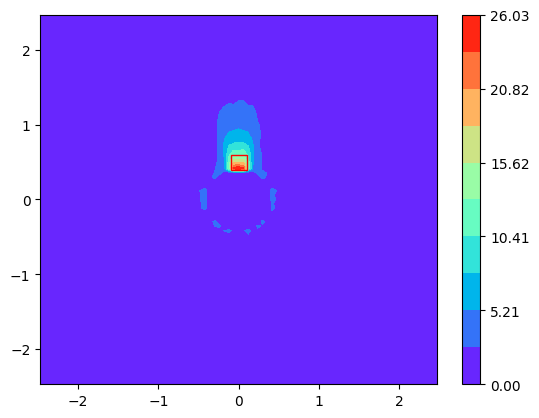

In [13]:
# Plotting UCSF
figu, axu = plt.subplots()
Xvu, Yvu = np.meshgrid(Xu, Yu, indexing='ij')
contouru = axu.contourf(Xvu, Yvu, energyu, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")

region = patches.Rectangle((x0, y0), roi_side, roi_side, linewidth=1, edgecolor='r', facecolor='none')
axu.add_patch(region)

cbaru = figu.colorbar(contouru)

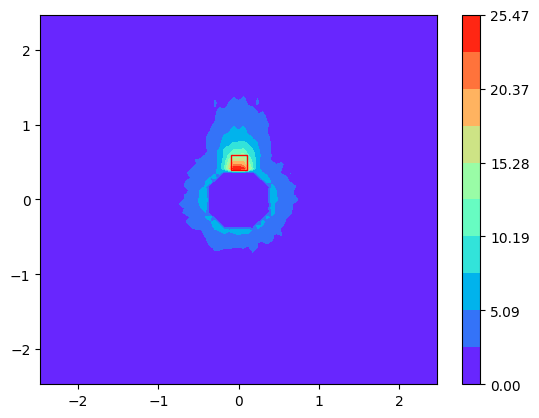

In [14]:
# Plotting MOSH
figm, axm = plt.subplots()
Xvm, Yvm = np.meshgrid(Xm, Ym, indexing='ij')
contourm = axm.contourf(Xvm, Yvm, energym, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")

region = patches.Rectangle((x0, y0), roi_side, roi_side, linewidth=1, edgecolor='r', facecolor='none')
axm.add_patch(region)

cbarm = figm.colorbar(contourm)

Next, we'll extract the energy along a constant-angle line to the center of the ROI.

In [15]:
# Define center of ROI
roi_center = (x0 + roi_side/2, y0 + roi_side/2)
print(roi_center)

# Compute angle from origin to roi_center
theta = np.arctan2(roi_center[1], roi_center[0])
print(theta) # pi/2, as expected for this example

# Compute distance from origin to roi_center
roi_rad = np.sqrt(roi_center[0]**2 + roi_center[1]**2)

(0.0, 0.5)
1.5707963267948966


In [16]:
# Extract energy along theta = pi/2 

error = 0.025 # cm

# UCSF
lin_ucsf, const_rad_ucsf = energy_along_theta(ucsf, theta, (bins_ucsf, bins_ucsf), dose_grid_half_ucsf, 
                                              source_plane_ucsf, err=error, radius=applicator_rad + 0.05, scale=True, norm_energy=norm_energy_u, dose=dose)

# MOSH
lin_mosh, const_rad_mosh = energy_along_theta(mosh, theta, (bins_mosh, bins_mosh), dose_grid_half_mosh, 
                                              source_plane_mosh, err=error, radius=applicator_rad + 0.05, scale=True, norm_energy=norm_energy_m, dose=dose)

# Extract arrays to plot dose as function of radius @ constant theta
# USCF
xu, yu, std_dev_sum_u, std_dev_mean_u, __ = plotter_1D(lin_ucsf, plot_rng=(0.30, 1.0), std_dev=True, num_Hx=1e7)

# MOSH
xm, ym, std_dev_sum_m, std_dev_mean_m, __ = plotter_1D(lin_mosh, plot_rng=(0.30, 1.0), std_dev=True, num_Hx=1e7)

<ErrorbarContainer object of 3 artists>

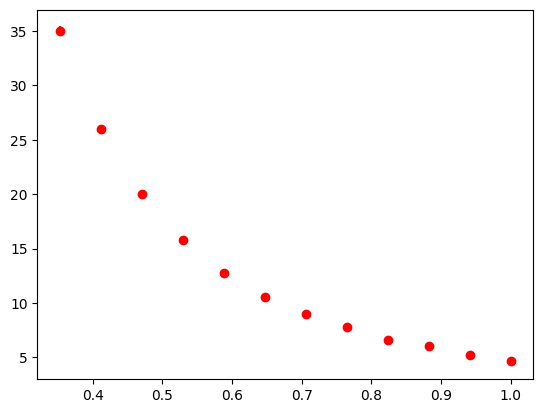

In [17]:
# Plot UCSF
fig1, ax1 = plt.subplots()
#ax1.scatter(xu, yu, color="red")
ax1.errorbar(xu, yu, yerr=std_dev_sum_u, fmt="ro")

<ErrorbarContainer object of 3 artists>

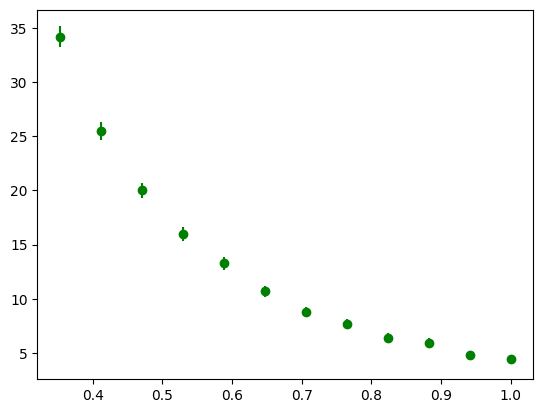

In [18]:
# Plot MOSH
fig2, ax2 = plt.subplots()
#ax2.scatter(xm, ym, color="green")
ax2.errorbar(xm, ym, yerr=std_dev_sum_m, fmt="go")

<ErrorbarContainer object of 3 artists>

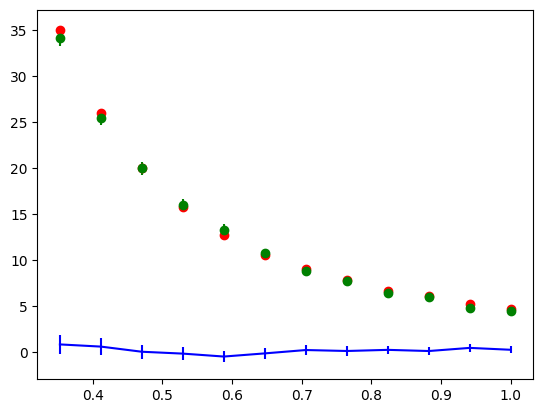

In [19]:
# Plot MOSH and UCSF together
fig7, ax7 = plt.subplots()
ax7.errorbar(xu, yu, yerr=std_dev_sum_u, fmt="ro")
ax7.errorbar(xm, ym, yerr=std_dev_sum_m, fmt="go")

# Plot the difference between the curves, with combined standard deviation
error_quad = np.sqrt(std_dev_sum_u**2 + std_dev_sum_m**2)
ax7.errorbar(xu, yu - ym, yerr=error_quad, linestyle="-", color="blue")

Next, we'll compute the mucosal dose at r = 0.35 cm (just outside edge of applicator)

In [20]:
# Note that the data was already extracted when calling energy_along_theta above

# Extract arrays to plot dose as function of theta @ constant radius = 0.35 cm
# USCF
thetau, yu, std_dev_sum_theta_u, __, __ = plotter_1D(const_rad_ucsf, ind_var=1, std_dev=True, num_Hx=1e7)

# MOSH
thetam, ym, std_dev_sum_theta_m, __, __ = plotter_1D(const_rad_mosh, ind_var=1, std_dev=True, num_Hx=1e7)

<ErrorbarContainer object of 3 artists>

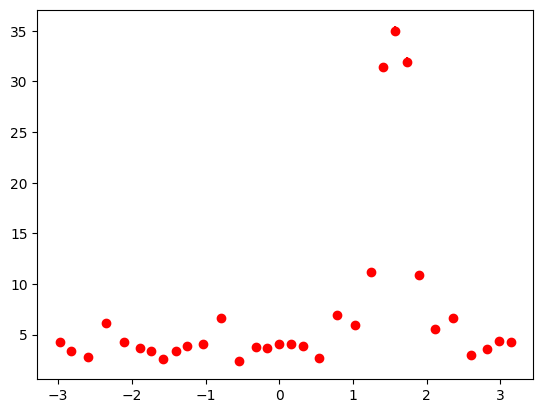

In [21]:
# Plot UCSF
fig3, ax3 = plt.subplots()
#ax3.scatter(thetau, yu, color="red")
ax3.errorbar(thetau, yu, yerr=std_dev_sum_theta_u, fmt="ro")

<ErrorbarContainer object of 3 artists>

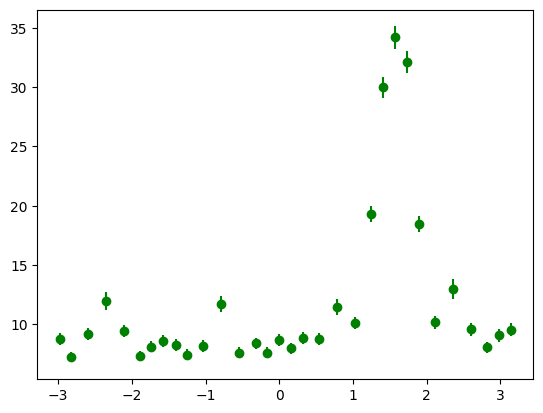

In [22]:
# Plot MOSH
fig4, ax4 = plt.subplots()
#ax4.scatter(thetam, ym, color="green")
ax4.errorbar(thetam, ym, yerr=std_dev_sum_theta_m, fmt="go")

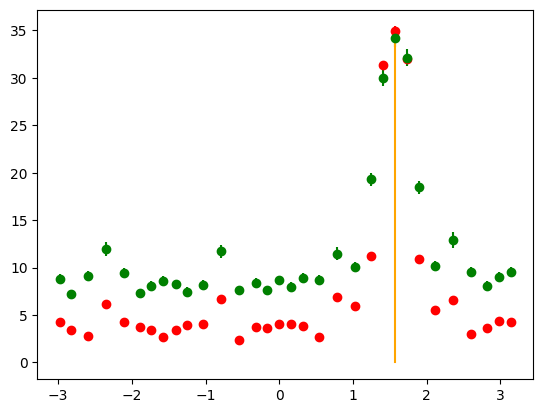

In [23]:
# Plot MOSH and UCSF together
fig8, ax8 = plt.subplots()
ax8.errorbar(thetau, yu, yerr=std_dev_sum_theta_u, fmt="ro")
ax8.errorbar(thetam, ym, yerr=std_dev_sum_theta_m, fmt="go")

# Bar indicating angle of max dose = pi/2
ybar = np.arange(0, 35, step=0.5)
xbar = np.ones(np.shape(ybar))*pi/2
ax8.plot(xbar, ybar, color="orange")

We'll also plot the dose as a function of angle away from the ROI (e.g. theta = 0) to compare dose distribution.

In [24]:
# Extract energy at constant angle theta = pi (x-axis)

non_roi_theta = pi

# UCSF
lin_ucsf_2, __ = energy_along_theta(ucsf, non_roi_theta, (bins_ucsf, bins_ucsf), dose_grid_half_ucsf, 
                                    source_plane_ucsf, err=0.001, scale=True, norm_energy=norm_energy_u, dose=dose)

# MOSH
lin_mosh_2, __ = energy_along_theta(mosh, non_roi_theta, (bins_mosh, bins_mosh), dose_grid_half_mosh, 
                                    source_plane_mosh, err=0.001, scale=True, norm_energy=norm_energy_m, dose=dose)

In [25]:
# Extract arrays to plot energy at angle theta = pi (x-axis)

# Extract arrays to plot dose as function of radius @ constant theta
# USCF
xu_2, yu_2, std_dev_sum_u_2, __, __ = plotter_1D(lin_ucsf_2, plot_rng=(0.30, 1.0), std_dev=True, num_Hx=1e7)

# MOSH
xm_2, ym_2, std_dev_sum_m_2, __, __ = plotter_1D(lin_mosh_2, plot_rng=(0.30, 1.0), std_dev=True, num_Hx=1e7)

<ErrorbarContainer object of 3 artists>

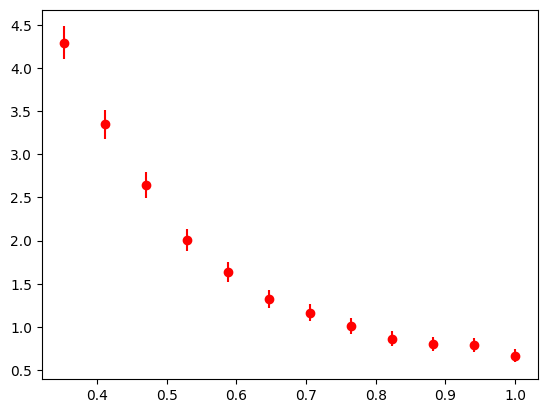

In [26]:
# Plot UCSF
fig5, ax5 = plt.subplots()
ax5.errorbar(xu_2, yu_2, yerr=std_dev_sum_u_2, fmt="ro")

<ErrorbarContainer object of 3 artists>

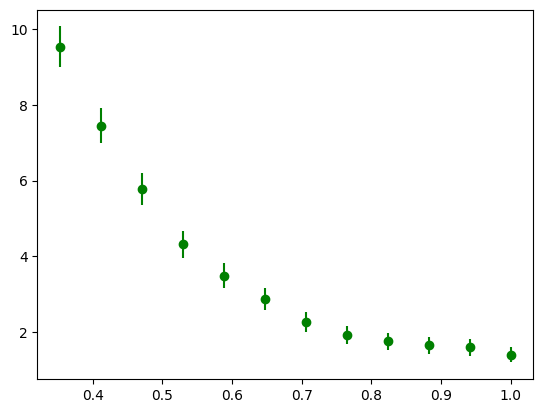

In [27]:
# Plot MOSH
fig6, ax6 = plt.subplots()
ax6.errorbar(xm_2, ym_2, yerr=std_dev_sum_m_2, fmt="go")

<ErrorbarContainer object of 3 artists>

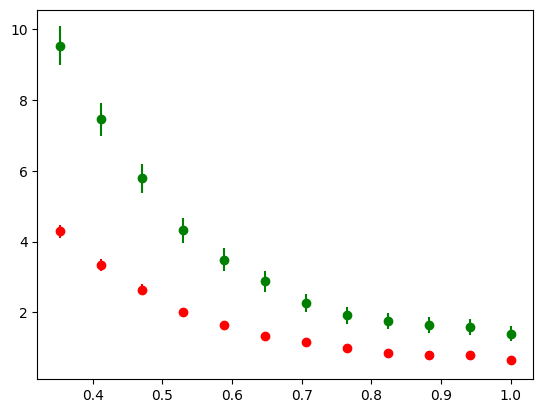

In [28]:
# Plot MOSH and UCSF together
fig9, ax9 = plt.subplots()
ax9.errorbar(xu_2, yu_2, yerr=std_dev_sum_u_2, fmt="ro")
ax9.errorbar(xm_2, ym_2, yerr=std_dev_sum_m_2, fmt="go")

## Subtracting contour plots

Another way to visualize the MOSH vs UCSF difference is to subtract the two distributions and observe areas of difference directly on a contour plot.

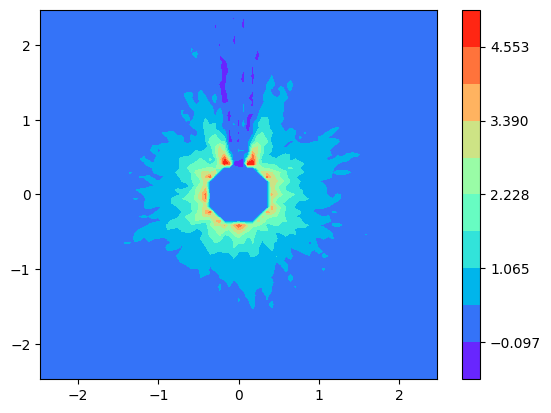

In [29]:
# Constructing UCSF - MOSH dose distribution
difference = energym - energyu

fig10, ax10 = plt.subplots()
contour_diff = ax10.contourf(Xvu, Yvu, difference, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")

#region = patches.Rectangle((x0, y0), roi_side, roi_side, linewidth=1, edgecolor='r', facecolor='none')
#axm.add_patch(region)

cbarm = figm.colorbar(contour_diff)